# Notebook created with Figure code cleaner

In [1]:
import os
import sys
import pickle
import importlib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

os.chdir('/project2/yangili1/cfbuenabadn/torino_paper/analysis')
sys.path.append('/project2/yangili1/cfbuenabadn/torino/scripts')
sys.path.append('/project2/yangili1/cfbuenabadn/torino_paper/code/scripts')
sys.path.append('/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure2')

import Figure2_plot_helpers
importlib.reload(Figure2_plot_helpers)

from Figure2_plot_helpers import (
    plot_torino_gene_annot_pct,
    plot_torino_annot_transcripts,
    plot_upset_isoforms,
    plot_gencode_v_torino_introns,
    plot_srsf3_gencode_a,
    plot_srsf3_gencode_b,
    plot_utrs_srsf3,
    plot_correlation_with_counts,
    plot_srsf3_long_reads_a,
    plot_srsf3_long_reads_b,
    plot_srsf3_long_reads_loadings,
    plot_syngr1_long_reads_a,
    plot_syngr1_long_reads_b,
    plot_syngr1_long_reads_c,
    plot_syngr1_long_reads_loadings,
    plot_isoform_annotations,
)

## Data

All preprocessing lives in `notebooks/Figure2/prepare_figure2_data.py` — this notebook only
unpickles what that script wrote to `figure_data/`. A full run takes ~8 min and peaks at
~4 GB, so give it a compute node:

```
sinteractive --mem=16G --time=1:00:00
cd /project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure2
/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/bin/python prepare_figure2_data.py
```

`--list` shows the steps and which pickles already exist; steps with an existing pickle
are skipped unless you pass `--force`.

In [2]:
data_dir = '../notebooks/Figure2/figure_data'


def load_pkl(name):
    with open(os.path.join(data_dir, name), 'rb') as f:
        return pickle.load(f)


# torino_gene_annot_pct / torino_annot_transcripts / upset_isoforms
gene_pct_df = load_pkl('gene_pct_df.pkl')
tx_count_df = load_pkl('tx_count_df.pkl')
df_upset = load_pkl('df_upset.pkl')

# gencode_v_torino_introns
_im = load_pkl('intron_matrices.pkl')
gencode_X, torino_X = _im['gencode_X'], _im['torino_X']

# SRSF3.gencode -- Version B
_sg = load_pkl('srsf3_gencode_b.pkl')
gencode_exons_v44, xlim_srsf3 = _sg['gencode_exons_v44'], _sg['xlim']

# UTRs_SRSF3
_utr = load_pkl('utrs_srsf3.pkl')
coverage_data = _utr['coverage_data']
utr_start, utr_end = _utr['start'], _utr['end']
ref_chain_iso_srsf3 = _utr['ref_chain_iso_srsf3']
gencode_iso_plot_relevant = _utr['gencode_iso_plot_relevant']
relevant_gencode_transcripts = _utr['relevant_gencode_transcripts']

# GTEx.LongRead_vs_ShorRead.Correlation
_corr = load_pkl('correlation.pkl')
corr_df = _corr['corr_df']
n_brain_sr, n_muscle_sr = _corr['n_brain_sr'], _corr['n_muscle_sr']

# Tables shared by the long reads panels. Subset to SRSF3 + SYNGR1 by the
# prep script (every plot below subsets to one gene anyway) — that is what
# keeps this a few MB instead of 1.6 GB.
_lr = load_pkl('long_reads_shared.pkl')
isoform_bed = _lr['isoform_bed']
gtf_bed = _lr['gtf_bed']
lr_table_str = _lr['lr_table_str']
annot_lr = _lr['annot_lr']
human_EL = _lr['human_EL']
human_metadata = _lr['human_metadata']

# SRSF3.long_reads
_s3 = load_pkl('srsf3_long_reads.pkl')
lr_bed_br_srsf3 = _s3['lr_bed_br']
iso_dict_br_srsf3 = _s3['iso_dict_br']
lr_bed_ms_srsf3 = _s3['lr_bed_ms']
iso_dict_ms_srsf3 = _s3['iso_dict_ms']

# SYNGR1.long_reads
_sy = load_pkl('syngr1_long_reads.pkl')
lr_bed_br_syngr1 = _sy['lr_bed_br']
iso_dict_br_syngr1 = _sy['iso_dict_br']
lr_bed_ms_syngr1 = _sy['lr_bed_ms']
iso_dict_ms_syngr1 = _sy['iso_dict_ms']

# LongReadPlots.py only defines functions (no module-scope data), and the
# plotting cells below need several of them.
%run LongReadPlots.py

print('loaded:', sorted(os.listdir(data_dir)))

custom-made modules
loaded: ['correlation.pkl', 'df_upset.pkl', 'gene_pct_df.pkl', 'intron_matrices.pkl', 'long_reads_shared.pkl', 'srsf3_gencode_b.pkl', 'srsf3_long_reads.pkl', 'syngr1_long_reads.pkl', 'tx_count_df.pkl', 'utrs_srsf3.pkl']


## torino_gene_annot_pct
Source: `analysis/Appris_1.ipynb` (Cell 107)

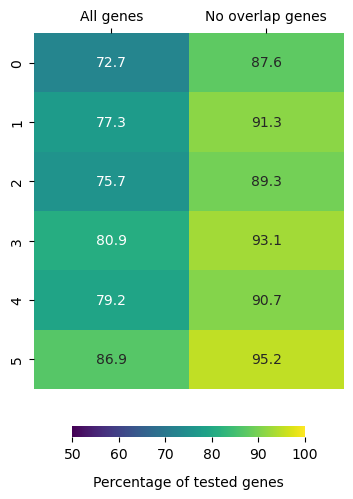

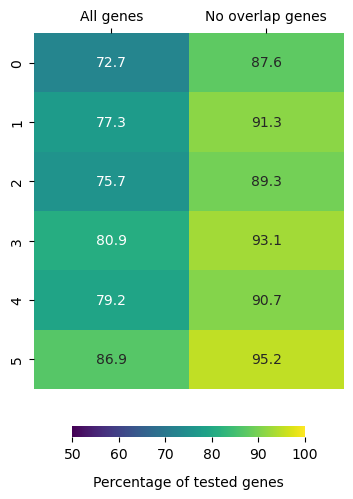

In [3]:
# Source: analysis/Appris_1.ipynb (Cell 107)
plot_torino_gene_annot_pct(gene_pct_df)

# plt.savefig('../code/results/figures/revision/fig2/torino_gene_annot_pct.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/revision/fig2/torino_gene_annot_pct.png', bbox_inches='tight', dpi=500)

## torino_annot_transcripts
Source: `analysis/Appris_1.ipynb` (Cell 116)

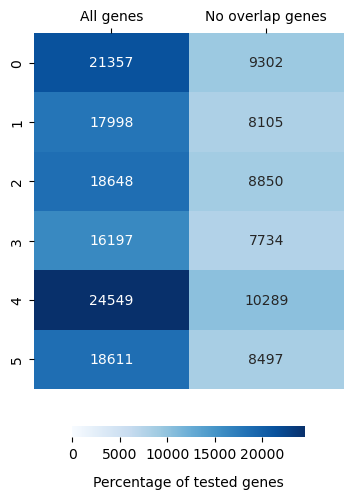

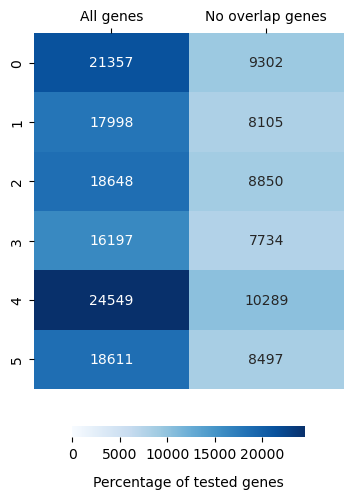

In [4]:
# Source: analysis/Appris_1.ipynb (Cell 116)
plot_torino_annot_transcripts(tx_count_df)

# plt.savefig('../code/results/figures/revision/fig2/torino_annot_transcripts.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/revision/fig2/torino_annot_transcripts.png', bbox_inches='tight', dpi=500)

## upset_isoforms
Source: `analysis/Appris_1.ipynb` (Cell 122)

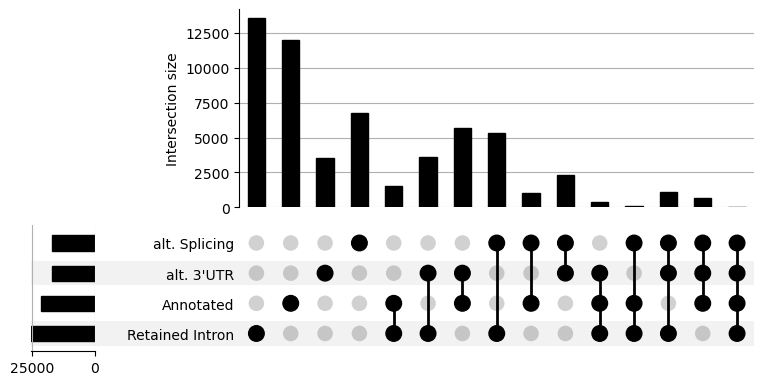

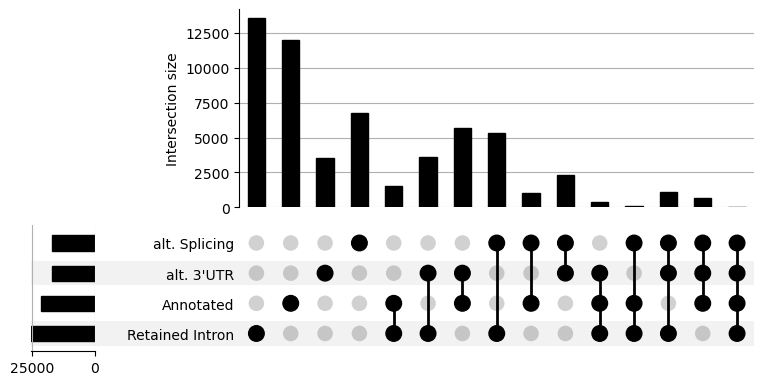

In [5]:
# Source: analysis/Appris_1.ipynb (Cell 122)
plot_upset_isoforms(df_upset)

# plt.savefig('../code/results/figures/revision/fig2/upset_isoforms.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/revision/fig2/upset_isoforms.png', bbox_inches='tight', dpi=500)

## gencode_v_torino_introns
Source: `analysis/Retained_Introns_figure.ipynb` (Cell 230, Path A: precomputed CSVs)

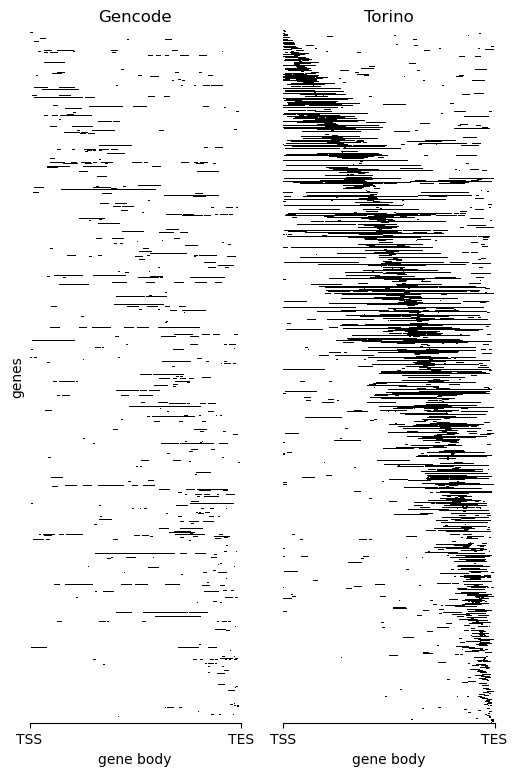

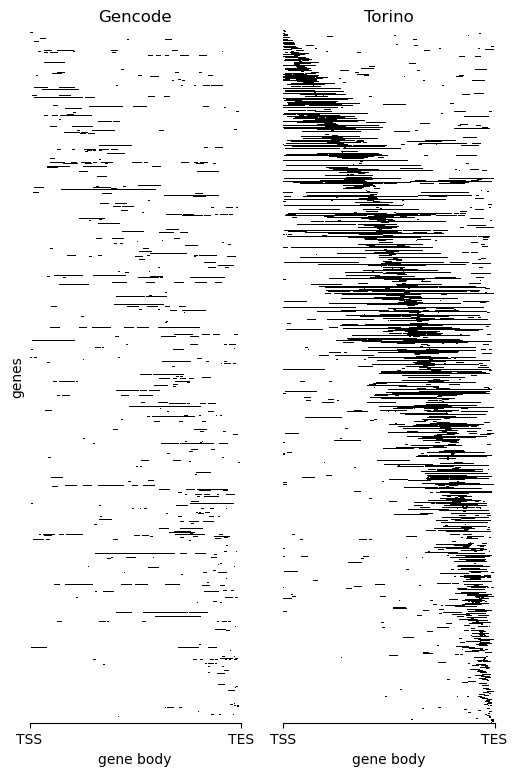

In [6]:
# Source: analysis/Retained_Introns_figure.ipynb (Cell 230)
plot_gencode_v_torino_introns(gencode_X, torino_X)

# plt.savefig('../code/results/figures/Fig2_isoforms/gencode_v_torino_introns.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/Fig2_isoforms/gencode_v_torino_introns.png', bbox_inches='tight', dpi=500)

## SRSF3.gencode -- Version A
Source: `analysis/Fig2_LongReads.ipynb` (Cell 188)

Uses `exons.all.bed.gz`, black colors, `LongReadPlots.py` `plot_isoform_annotations`.

In [7]:
# # Source: analysis/Fig2_LongReads.ipynb (Cell 188)
# # plot_isoform_annotations imported from Figure2_plot_helpers (originally from load_human.py)
# plot_srsf3_gencode_a(gtf_bed, plot_isoform_annotations)

# # plt.savefig('../code/results/figures/Fig2_isoforms/SRSF3.gencode.pdf', bbox_inches='tight')
# # plt.savefig('../code/results/figures/Fig2_isoforms/SRSF3.gencode.png', bbox_inches='tight', dpi=500)

## SRSF3.gencode -- Version B
Source: `gtex-stm/analysis/Figure_1A_scratch.ipynb` (Cell 40)

Uses `gencode.v44` annotation, navy colors, 9-row subplot with custom x-axis.

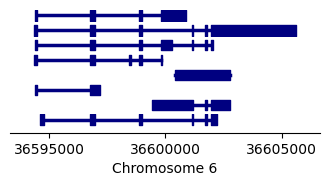

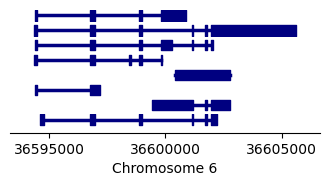

In [8]:
# Source: gtex-stm/analysis/Figure_1A_scratch.ipynb (Cell 40)
plot_srsf3_gencode_b(gencode_exons_v44, xlim_srsf3)

# plt.savefig('/project2/mstephens/cfbuenabadn/gtex-stm/code/scratch_figures/figure1/SRSF3.gencode.pdf', bbox_inches='tight')
# plt.savefig('/project2/mstephens/cfbuenabadn/gtex-stm/code/scratch_figures/figure1/SRSF3.gencode.png', bbox_inches='tight', dpi=500)

## UTRs_SRSF3
Source: `analysis/UTR3.ipynb` (Cell 316)

Uses gencode_iso_plot Version A (from `exons.all.bed.gz`).

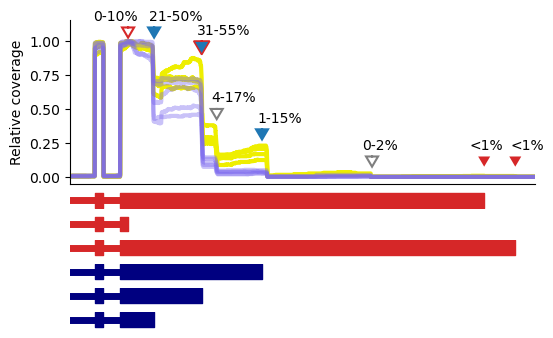

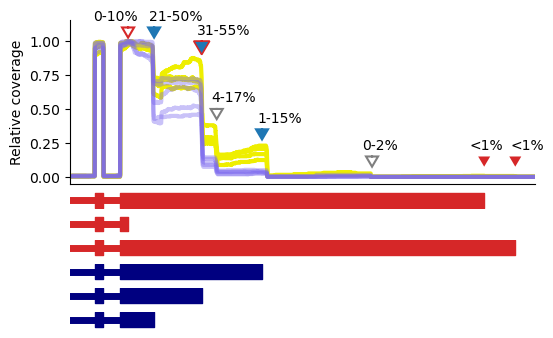

In [9]:
# Source: analysis/UTR3.ipynb (Cell 316)
from torino_plots import plot_isoform_annotations as plot_isoform_annotations_torino

plot_utrs_srsf3(coverage_data, ref_chain_iso_srsf3, gencode_iso_plot_relevant,
                relevant_gencode_transcripts, plot_isoform_annotations_torino,
                utr_start, utr_end)

# plt.savefig('../code/results/figures/revision/fig2/UTRs_SRSF3.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/revision/fig2/UTRs_SRSF3.png', bbox_inches='tight', dpi=500)

## GTEx.LongRead_vs_ShorRead.Correlation
Source: `analysis/Fig2_LongReads.ipynb` (Cell 194)

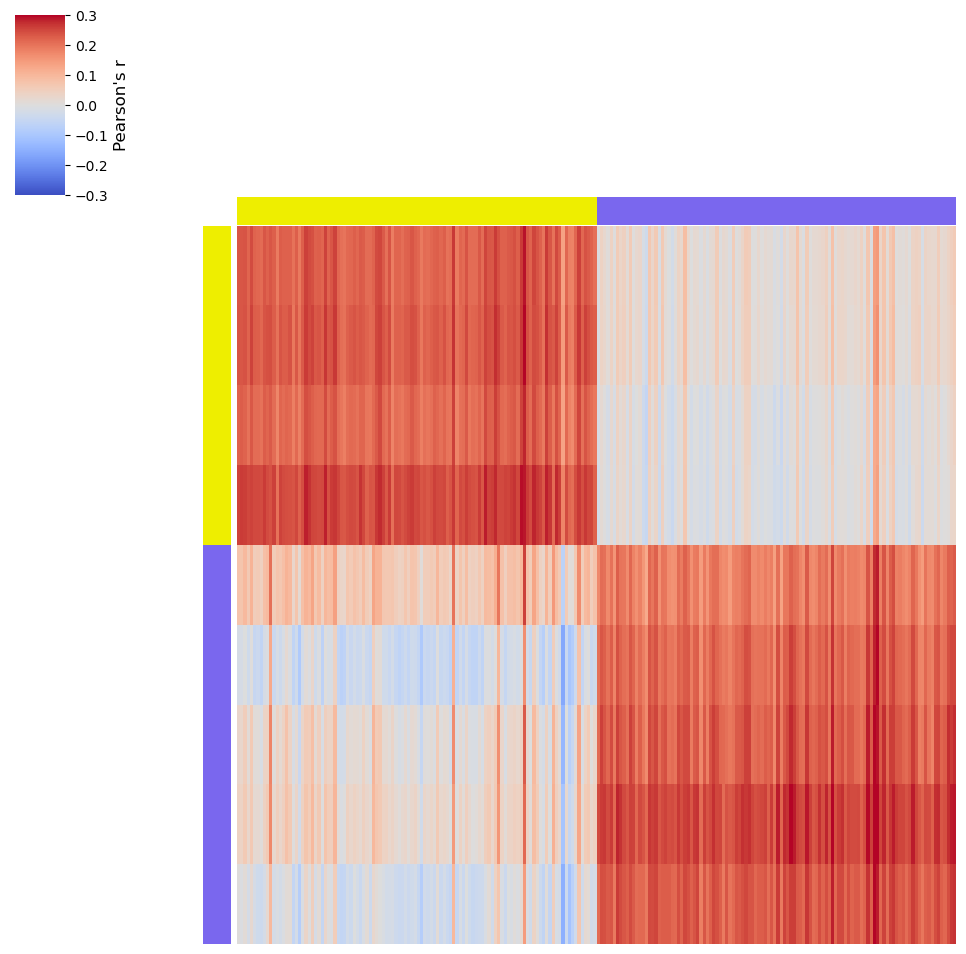

In [10]:
# Source: analysis/Fig2_LongReads.ipynb (Cell 194)
plot_correlation_with_counts(corr_df, n_brain_sr, n_muscle_sr)

# plt.savefig('../code/results/figures/Fig2_isoforms/GTEx.LongRead_vs_ShorRead.Correlation.pdf', bbox_inches='tight')
# plt.savefig('../code/results/figures/Fig2_isoforms/GTEx.LongRead_vs_ShorRead.Correlation.png', bbox_inches='tight', dpi=500)

## SRSF3.long_reads -- Version A
Source: `analysis/Fig2_LongReads_Definitive.ipynb` (Cell 15)

All isoforms from `isoform_dict_br`.

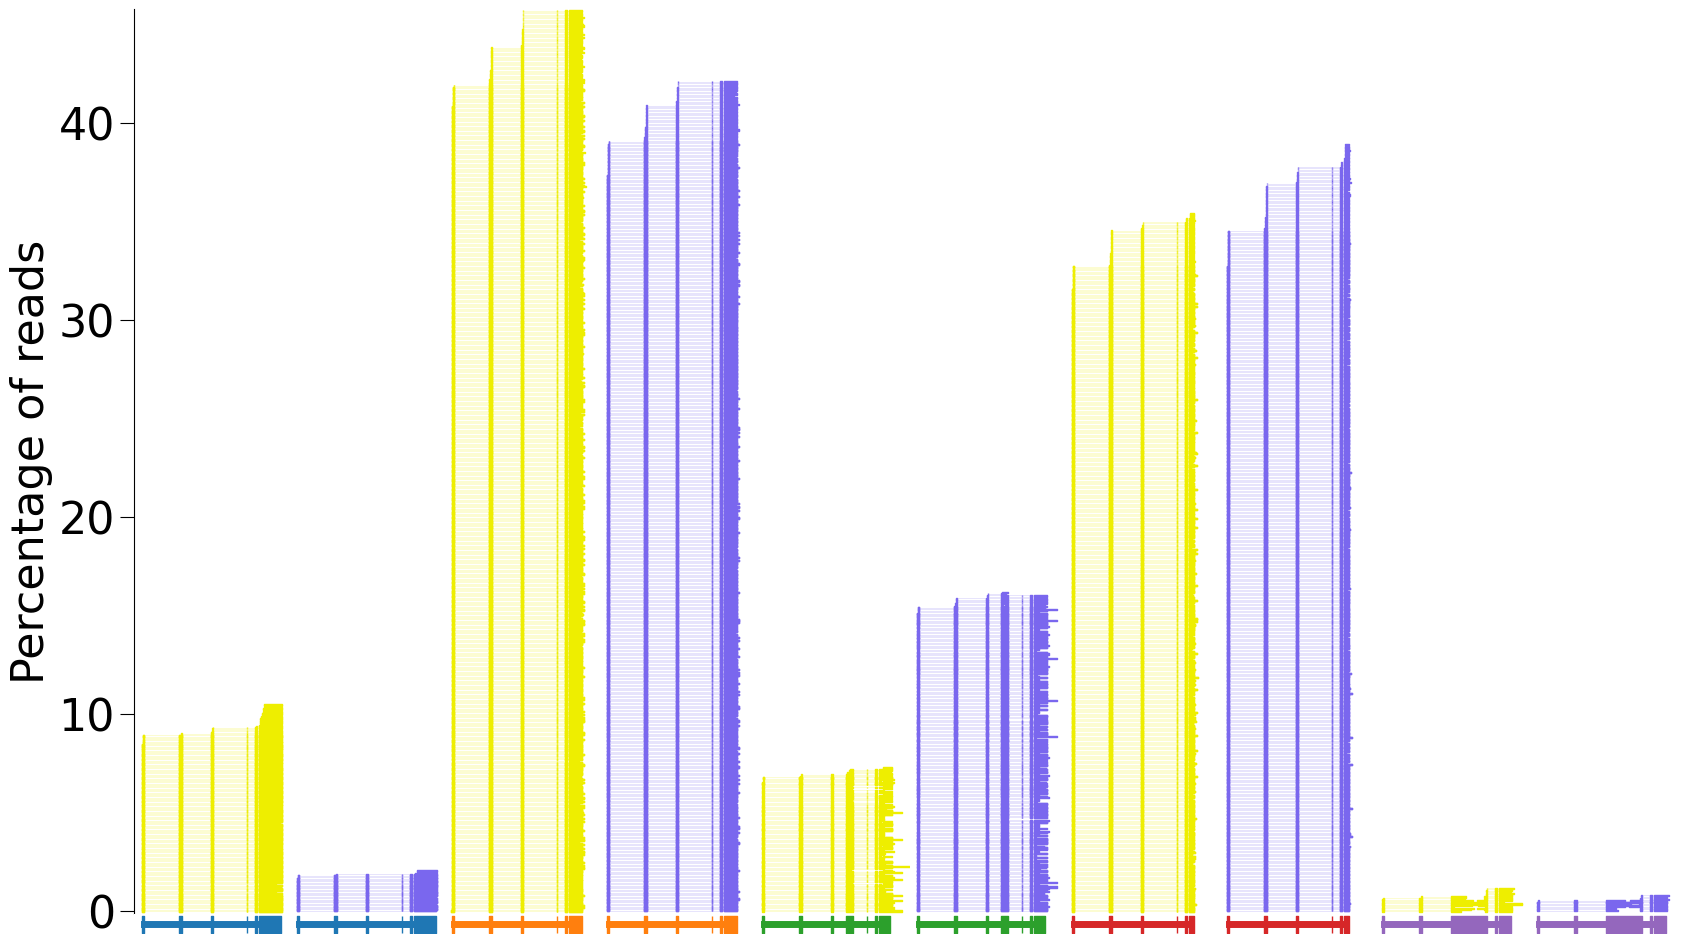

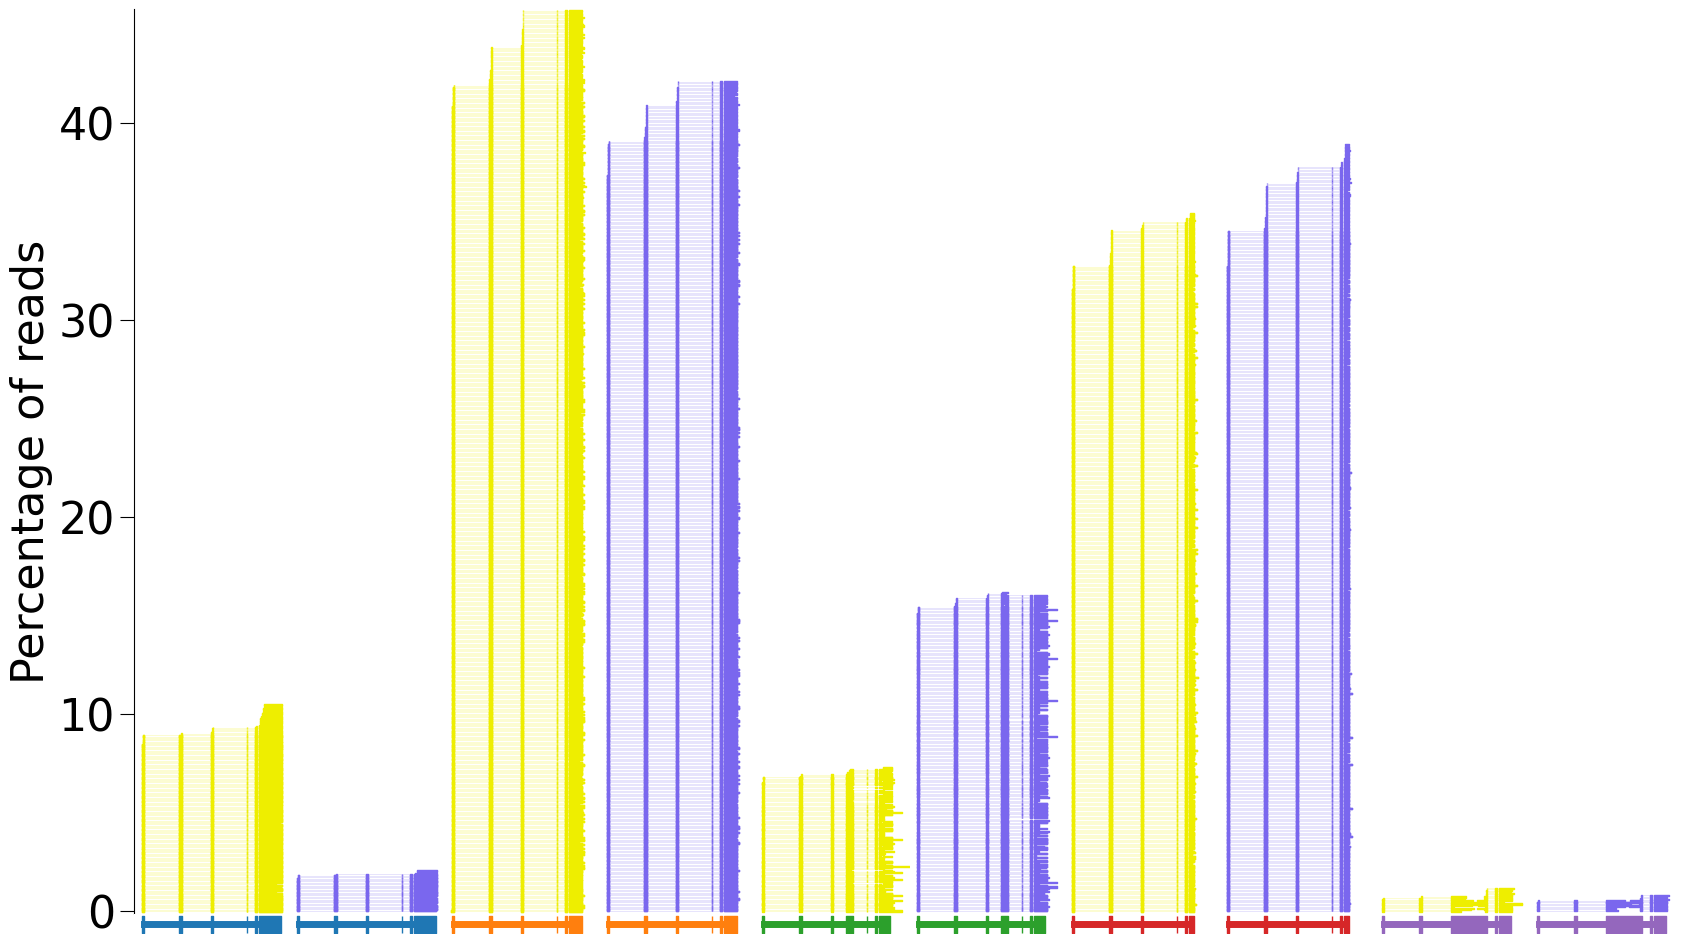

In [11]:
# Source: analysis/Fig2_LongReads_Definitive.ipynb (Cell 15)
plot_srsf3_long_reads_a(isoform_bed, lr_bed_br_srsf3, lr_bed_ms_srsf3,
                        iso_dict_br_srsf3, iso_dict_ms_srsf3,
                        plot_gene_long_read_transcripts_comparison_single_ax)

# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads.pdf', bbox_inches='tight', dpi=500)
# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads.png', bbox_inches='tight', dpi=500)

## SRSF3.long_reads -- Version B
Source: `analysis/LongReads2.ipynb` (Cell 30)

Isoforms 2-6 only.

In [12]:
# # Source: analysis/LongReads2.ipynb (Cell 30)
# plot_srsf3_long_reads_b(isoform_bed, lr_bed_br_srsf3, lr_bed_ms_srsf3,
#                         iso_dict_br_srsf3, iso_dict_ms_srsf3,
#                         plot_gene_long_read_transcripts_comparison_single_ax)

# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads.pdf', bbox_inches='tight')
# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads.png', bbox_inches='tight', dpi=500)

## SRSF3.long_reads_loadings
Source: `analysis/Fig2_LongReads_Definitive.ipynb` (Cell 19)

NOTE: `plot_loadings_vs_longreads` both computes and plots (deeply interleaved). Will recompute on pickle re-runs.

PearsonRResult(statistic=np.float64(0.8296528022130703), pvalue=np.float64(0.002983068901039436))


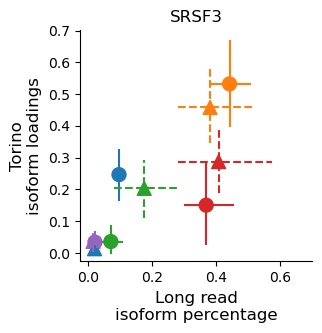

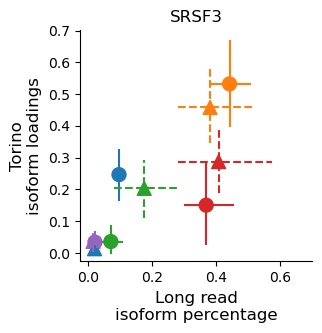

In [13]:
# Source: analysis/Fig2_LongReads_Definitive.ipynb (Cell 19)
plot_srsf3_long_reads_loadings(human_EL, lr_table_str, annot_lr, human_metadata,
                               plot_loadings_vs_longreads)

# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads_loadings.pdf', bbox_inches='tight', dpi=500)
# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SRSF3.long_reads_loadings.png', bbox_inches='tight', dpi=500)

## SYNGR1.long_reads -- Version A
Source: `analysis/Fig2_LongReads_Definitive.ipynb` (Cell 27)

tab10 colors, y-axis 0-100%.

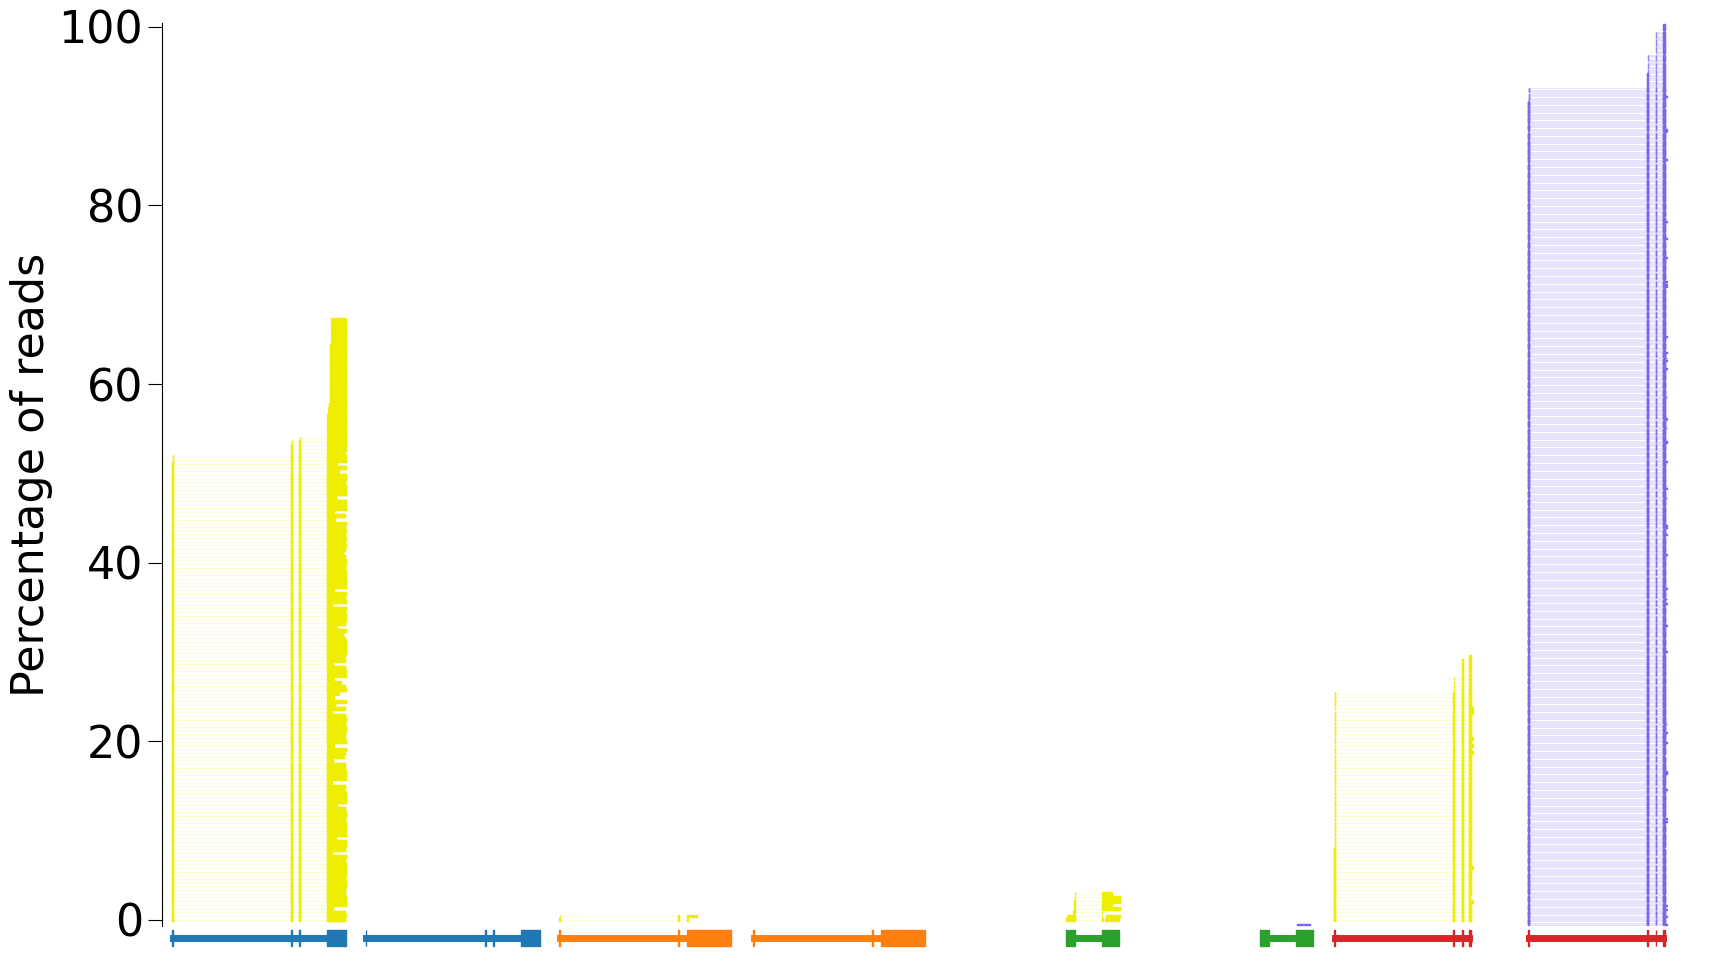

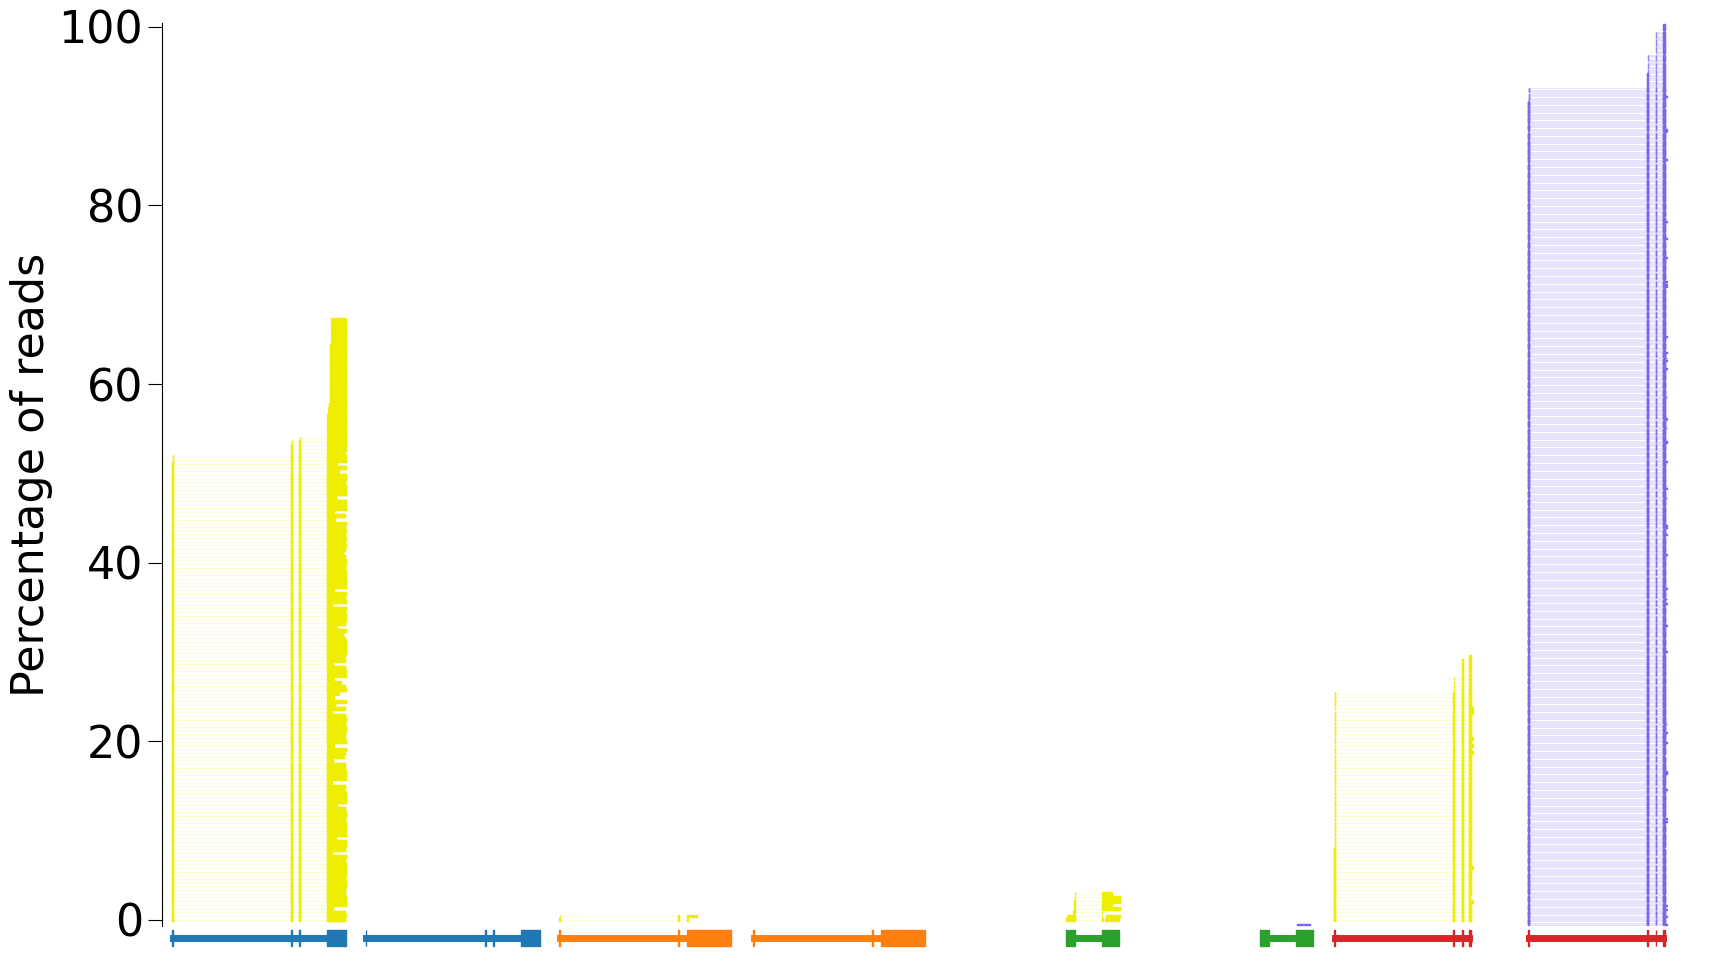

In [14]:
# Source: analysis/Fig2_LongReads_Definitive.ipynb (Cell 27)
plot_syngr1_long_reads_a(isoform_bed, lr_bed_br_syngr1, lr_bed_ms_syngr1,
                         iso_dict_br_syngr1, iso_dict_ms_syngr1,
                         plot_gene_long_read_transcripts_comparison_single_ax)

# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.pdf', bbox_inches='tight', dpi=500)
# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.png', bbox_inches='tight', dpi=500)

## SYNGR1.long_reads -- Version B
Source: `analysis/LongReads2.ipynb` (Cell 33)

tab10 colors, y-axis 0-40%.

In [15]:
# # Source: analysis/LongReads2.ipynb (Cell 33)
# plot_syngr1_long_reads_b(isoform_bed, lr_bed_br_syngr1, lr_bed_ms_syngr1,
#                          iso_dict_br_syngr1, iso_dict_ms_syngr1,
#                          plot_gene_long_read_transcripts_comparison_single_ax)

# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.pdf', bbox_inches='tight')
# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.png', bbox_inches='tight', dpi=500)

## SYNGR1.long_reads -- Version C
Source: `analysis/Fig2_LongReads.ipynb` (Cell 14)

navy colors, y-axis 0-100%.

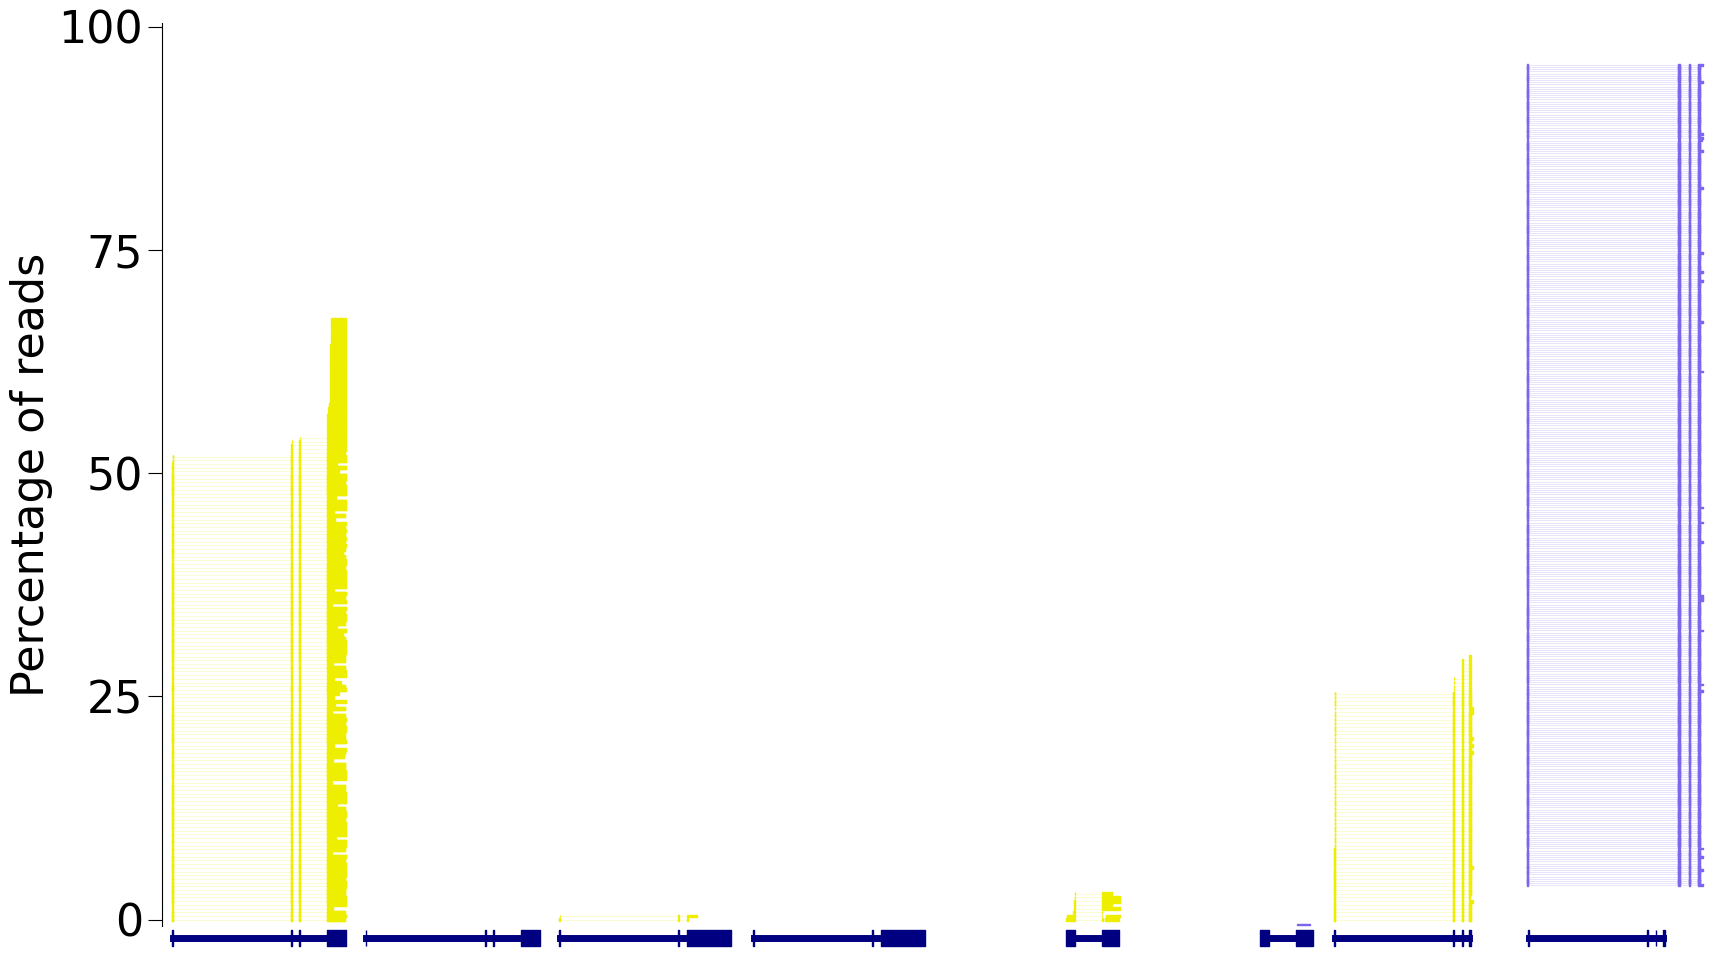

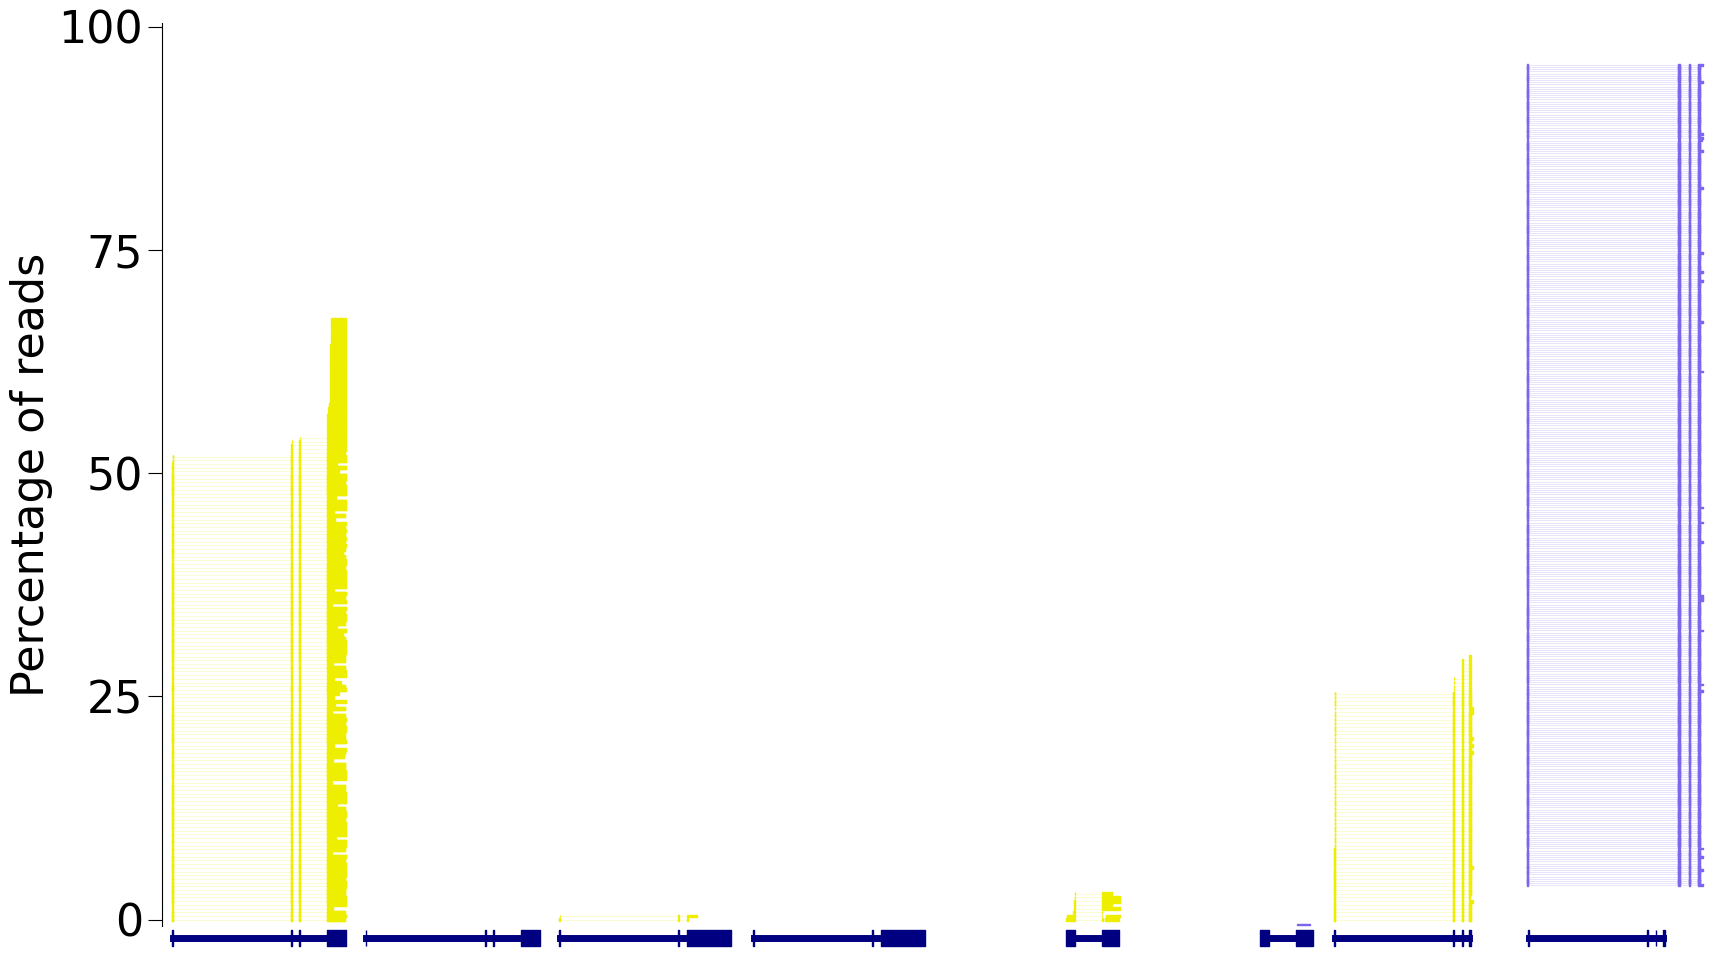

In [16]:
# # Source: analysis/Fig2_LongReads.ipynb (Cell 14)
# plot_syngr1_long_reads_c(isoform_bed, lr_bed_br_syngr1, lr_bed_ms_syngr1,
#                          iso_dict_br_syngr1, iso_dict_ms_syngr1,
#                          plot_gene_long_read_transcripts_comparison_single_ax)

# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.pdf', bbox_inches='tight')
# # plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads.png', bbox_inches='tight', dpi=500)

## SYNGR1.long_reads_loadings
Source: `analysis/Fig2_LongReads_Definitive.ipynb` (Cell 35)

NOTE: `plot_loadings_vs_longreads` both computes and plots (deeply interleaved). Will recompute on pickle re-runs.

PearsonRResult(statistic=np.float64(0.7591744316307513), pvalue=np.float64(0.02891480571041461))


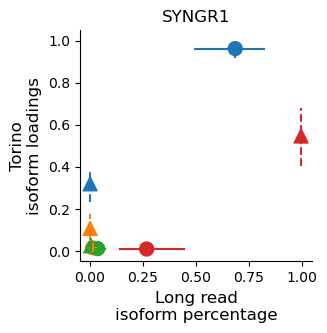

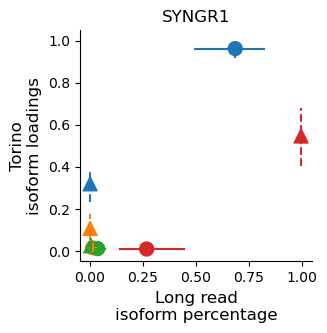

In [17]:
# Source: analysis/Fig2_LongReads_Definitive.ipynb (Cell 35)
plot_syngr1_long_reads_loadings(human_EL, lr_table_str, annot_lr, human_metadata,
                                plot_loadings_vs_longreads)

# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads_loadings.pdf', bbox_inches='tight', dpi=500)
# plt.savefig('../code/results/figures/Fig2_isoforms/long_reads/SYNGR1.long_reads_loadings.png', bbox_inches='tight', dpi=500)